# 01 - Exploratory Data Analysis (EDA)
**CSE303 Capstone: Intelligent Toxicity Moderation Platform** (Jigsaw Toxic Comment dataset)

In this notebook we only *look* at the data. Questions we want to answer:
1. How big is the data and is anything missing?
2. How imbalanced are the 6 labels?
3. Which labels occur together?
4. Do toxic comments look different (length, words)?
5. **Our twist:** do people really hide bad words using symbols/numbers (like `f*ck`, `1d10t`)? If yes, we need character-level features.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
RAW = Path("../data/raw")
PROC = Path("../data/processed")     # cleaned text + feature matrices made in notebook 02
MODELS = Path("../models")
ASSETS = Path("../assets")
for folder in (PROC, MODELS, ASSETS):
    folder.mkdir(exist_ok=True)

import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

Matplotlib is building the font cache; this may take a moment.


## 1. Load data

In [2]:
path = RAW / "train.csv"
if not path.exists():
    path = RAW / "train_sample.csv"
    print("train.csv not found, using the synthetic sample. Run download_data.py first!")

df = pd.read_csv(path)
print("File:", path.name)
print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
df.head()

File: train.csv
Shape: (159571, 8)

Missing values:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my username Hardcore Metallica Fan wer...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm seemingly stuck with. Thanks. ...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It's just that this guy is const...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on improvement - I wondered if th...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember what page that's on?",0,0,0,0,0,0


**Observation:** no missing values, so we do not need any imputation.

## 2. Class imbalance

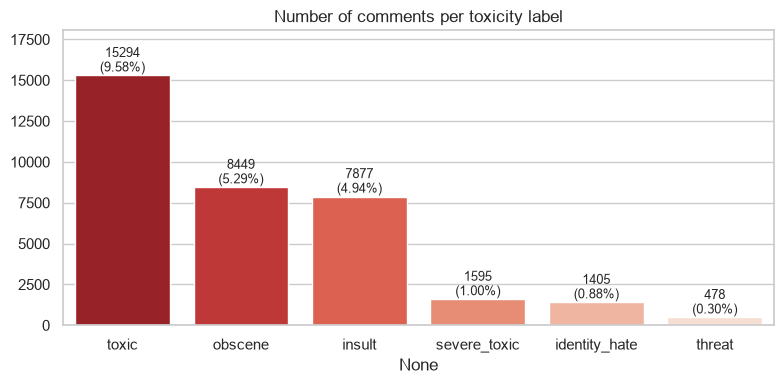

Comments with NO label at all: 89.8%


In [3]:
counts = df[LABELS].sum().sort_values(ascending=False)
percent = counts / len(df) * 100

plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, palette="Reds_r")
for i, (c, p) in enumerate(zip(counts.values, percent.values)):
    plt.text(i, c, f"{c}\n({p:.2f}%)", ha="center", va="bottom", fontsize=9)
plt.title("Number of comments per toxicity label")
plt.ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.savefig(ASSETS / "eda_class_imbalance.png", dpi=150)
plt.show()

no_label = (df[LABELS].sum(axis=1) == 0).mean() * 100
print(f"Comments with NO label at all: {no_label:.1f}%")

**Observation:** most comments are clean, and `threat` and `identity_hate` are very rare (well below 1% for `threat`). So *accuracy is a bad metric* here: a model that says "clean" for everything would score about 90% accuracy and catch nothing. We will use ROC-AUC and Macro F1.

## 3. How many labels does one comment have?

num_labels
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64


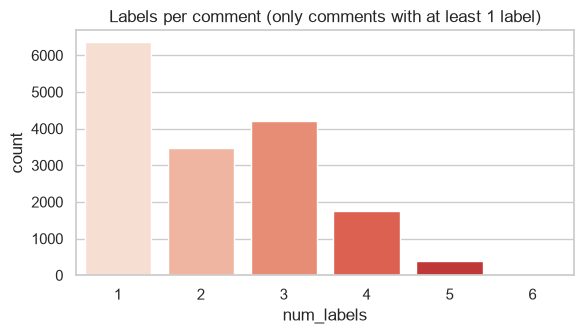

In [4]:
df["num_labels"] = df[LABELS].sum(axis=1)
print(df["num_labels"].value_counts().sort_index())

plt.figure(figsize=(6, 3.5))
sns.countplot(x="num_labels", data=df[df["num_labels"] > 0], palette="Reds")
plt.title("Labels per comment (only comments with at least 1 label)")
plt.tight_layout()
plt.savefig(ASSETS / "eda_labels_per_comment.png", dpi=150)
plt.show()

## 4. Label co-occurrence

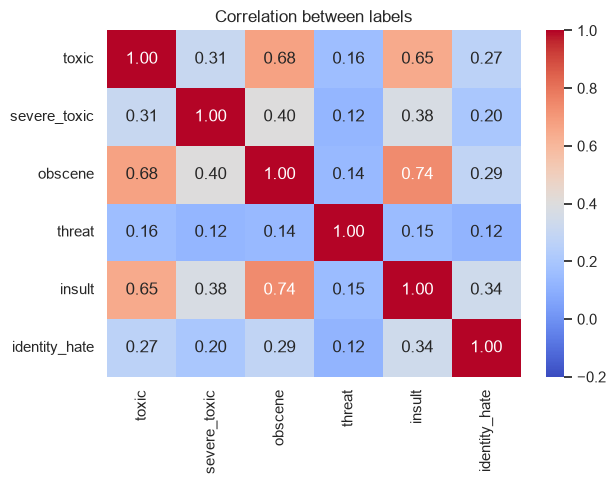

In [5]:
plt.figure(figsize=(6.5, 5))
sns.heatmap(df[LABELS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.2, vmax=1)
plt.title("Correlation between labels")
plt.tight_layout()
plt.savefig(ASSETS / "eda_label_correlation.png", dpi=150)
plt.show()

**Observation:** `toxic`, `obscene` and `insult` are strongly linked, so one comment often has several labels. That is why this is a *multi-label* problem.

## 5. Comment length: toxic vs clean

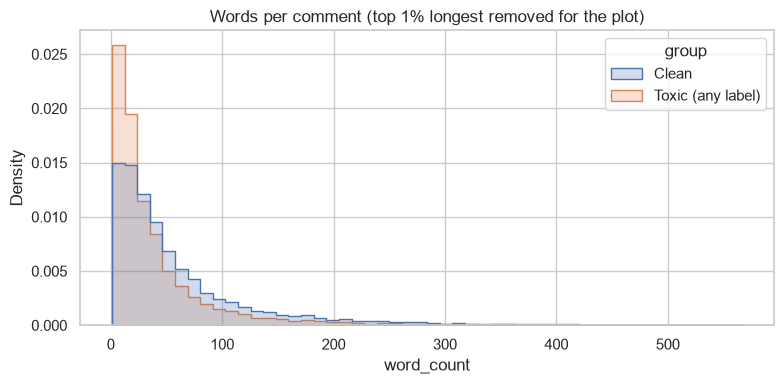

                   mean   50%     max
group                                
Clean              68.9  38.0  1250.0
Toxic (any label)  52.7  23.0  1411.0


In [6]:
df["word_count"] = df["comment_text"].astype(str).str.split().str.len()
df["group"] = np.where(df["num_labels"] > 0, "Toxic (any label)", "Clean")

plt.figure(figsize=(8, 4))
upper = df["word_count"].quantile(0.99)
sns.histplot(data=df[df["word_count"] <= upper], x="word_count", hue="group",
             bins=50, stat="density", common_norm=False, element="step")
plt.title("Words per comment (top 1% longest removed for the plot)")
plt.tight_layout()
plt.savefig(ASSETS / "eda_word_count.png", dpi=150)
plt.show()

print(df.groupby("group")["word_count"].describe()[["mean", "50%", "max"]].round(1))

**Observation:** toxic comments are usually shorter (median) than clean ones, but the two groups overlap a lot, so length alone cannot detect toxicity.

## 6. Most common words: toxic vs clean

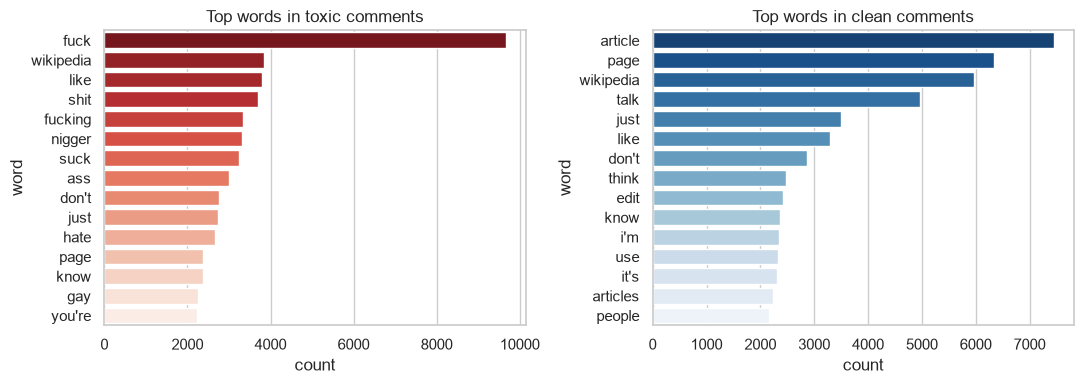

In [7]:
def top_words(texts, n=15):
    counter = Counter()
    for t in texts:
        words = re.findall(r"[a-z']+", str(t).lower())
        counter.update(w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2)
    return counter.most_common(n)

# use at most 20000 comments of each group to keep it fast
toxic_texts = df[df["num_labels"] > 0]["comment_text"].head(20000)
clean_texts = df[df["num_labels"] == 0]["comment_text"].head(20000)

top_toxic = pd.DataFrame(top_words(toxic_texts), columns=["word", "count"])
top_clean = pd.DataFrame(top_words(clean_texts), columns=["word", "count"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(y="word", x="count", data=top_toxic, ax=axes[0], palette="Reds_r")
axes[0].set_title("Top words in toxic comments")
sns.barplot(y="word", x="count", data=top_clean, ax=axes[1], palette="Blues_r")
axes[1].set_title("Top words in clean comments")
plt.tight_layout()
plt.savefig(ASSETS / "eda_top_words.png", dpi=150)
plt.show()

**Note:** the toxic chart contains offensive words because that is what the dataset contains. Clean comments are mostly Wikipedia talk-page words (article, page, edit...).

## 7. Our twist: do people hide bad words?

Spammers and trolls write `f*ck`, `sh!t`, `a$$`, `1d10t` or `i.d.i.o.t` to fool word-based filters. We count how many comments contain simple "disguise" patterns:

| Pattern | Example |
|---------|---------|
| letter + symbol + letter | `f*ck`, `sh!t`, `a$$hole` |
| letter + digit + letter | `1d10t`, `l0ser`, `m0ron` |
| dotted / spaced single letters | `i.d.i.o.t`, `s.t.u.p.i.d` |

These are rough regex patterns, so some matches are false alarms (e.g. a time like `a1b`), but the *difference between toxic and clean* is what matters.

,pattern,% of toxic comments,% of clean comments
0,letter-symbol-letter (f*ck),1.48,1.73
1,letter-digit-letter (l0ser),0.85,0.99
2,dotted letters (i.d.i.o.t),0.25,0.09


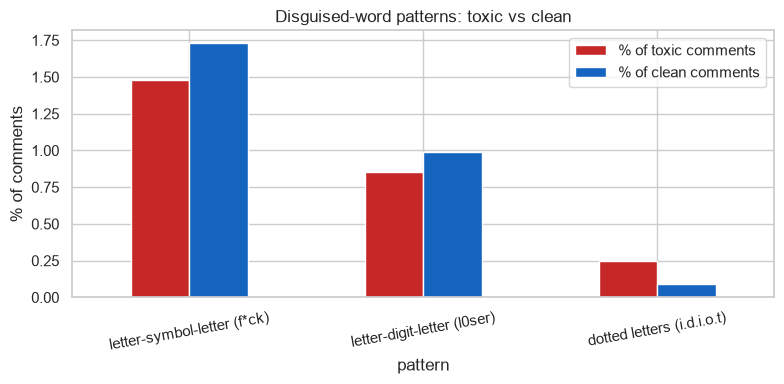

In [8]:
patterns = {
    "letter-symbol-letter (f*ck)": r"[a-z][\*@\$!#][a-z]",
    "letter-digit-letter (l0ser)": r"[a-z][0-9][a-z]",
    "dotted letters (i.d.i.o.t)": r"\b(?:[a-z][\.\-_]){3,}[a-z]\b",
}

text_lower = df["comment_text"].astype(str).str.lower()
is_toxic = df["num_labels"] > 0

rows = []
for name, pat in patterns.items():
    found = text_lower.str.contains(pat, regex=True)
    rows.append({"pattern": name,
                 "% of toxic comments": round(found[is_toxic].mean() * 100, 2),
                 "% of clean comments": round(found[~is_toxic].mean() * 100, 2)})

disguise = pd.DataFrame(rows)
display(disguise)

disguise.set_index("pattern").plot(kind="bar", figsize=(8, 4), rot=10, color=["#c62828", "#1565c0"])
plt.ylabel("% of comments")
plt.title("Disguised-word patterns: toxic vs clean")
plt.tight_layout()
plt.savefig(ASSETS / "eda_obfuscation_patterns.png", dpi=150)
plt.show()

In [9]:
# a few real examples of toxic comments with the letter-symbol-letter pattern
found = text_lower.str.contains(patterns["letter-symbol-letter (f*ck)"], regex=True) & is_toxic
examples = df[found]["comment_text"].str.replace("\n", " ").str[:110].head(5)
for e in examples:
    print("-", e)

- Your blatant POV pushing   Neither of you guys has made any contribution to this Italian history article other
- Thank you for your RACIST experimenting with the page Katherine Heigl on Wikipedia. Your test worked, and it h
- @KWW and father F*cker, u still didnt give no source haha:P what a sore f*cking loser haha:P
- Ekgograf and his son of bitch of gang of dumb, n*zi , and are the greatest batard that ever walk on earth !!!!
- Piss on me   P!SS ON ME, YOU BIMBO!


## Summary of EDA (what we learned and what we do next)
* Data has **no missing values**; labels are **highly imbalanced** (especially `threat`, `identity_hate`) -> use ROC-AUC + Macro F1, not accuracy.
* Labels overlap strongly -> **multi-label** (OneVsRest) setup.
* Length is a weak signal; the actual words matter.
* Disguised words are **rare (about 1% of comments)** and, with these crude regex patterns, are **not clearly more common in toxic comments** (only dotted letters like `i.d.i.o.t` show a small difference). So the obfuscation twist is a *robustness feature*, not a big accuracy gain - the capstone notebook checks this with a word-only vs hybrid ablation. We still add **character n-gram TF-IDF** next to word TF-IDF because it is cheap and also handles typos and word variants.

Next: `02_preprocessing.ipynb` (cleaning, split, features).